# Gemma 3 4B – Time & Space Complexity at Q4_0

Google's Gemma 3 4B Instruct, measured at **Q4_0 GGUF** quantization using llama-cpp-python.

This notebook measures:
- **Space complexity**: file size, runtime RAM, KV cache footprint
- **Time complexity**: prefill latency and decode throughput across sequence lengths

All data is saved to CSV/JSON and graphs are saved as PNG.

### Installation

In [1]:
import subprocess, sys, torch

if torch.cuda.is_available():
    print("CUDA detected – installing llama-cpp-python with CUDA support...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "llama-cpp-python",
        "--extra-index-url", "https://abetlen.github.io/llama-cpp-python/whl/cu121",
        "--quiet",
    ])
else:
    print("No CUDA – installing CPU-only llama-cpp-python...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "llama-cpp-python", "--quiet"])

print("llama-cpp-python ready.")

CUDA detected – installing llama-cpp-python with CUDA support...
llama-cpp-python ready.


### Step 1: Download Q4_0 GGUF

In [3]:
from huggingface_hub import hf_hub_download
import os

REPO_ID        = "bartowski/google_gemma-3-4b-it-GGUF"
FILENAME       = "google_gemma-3-4b-it-Q4_0.gguf"
TOTAL_PARAMS   = 4300000000   # approximate parameter count
MODEL_NAME     = "Gemma 3 4B"

print(f"Downloading {FILENAME} ...")
GGUF_PATH = hf_hub_download(repo_id=REPO_ID, filename=FILENAME)
file_bytes = os.path.getsize(GGUF_PATH)
file_gb    = file_bytes / 1024**3
print(f"Downloaded  → {GGUF_PATH}")
print(f"File size   → {file_gb:.3f} GB")

google_gemma-3-4b-it-Q4_0.gguf:   0%|          | 0.00/2.37G [00:00<?, ?B/s]

Downloaded  → /root/.cache/huggingface/hub/models--bartowski--google_gemma-3-4b-it-GGUF/snapshots/71506238f970075ca85125cd749c28b1b0eee84e/google_gemma-3-4b-it-Q4_0.gguf
File size   → 2.207 GB


---
## 2. Space Complexity

Q4_0 stores every weight block as 32 × 4-bit values plus one fp16 scale factor,
giving ~4.5 effective bits per weight.
`Memory ≈ total_params × 0.5625 bytes`

### 2a. File Size & Precision Comparison

In [4]:
print("=" * 58)
print(f"  {MODEL_NAME} – Space Complexity at Q4_0")
print("=" * 58)
print(f"  Total parameters (approx): {TOTAL_PARAMS/1e9:.3f} B")
print(f"  GGUF file size:            {file_gb:.3f} GB")
print(f"  Compression vs fp32:       {TOTAL_PARAMS*4/file_bytes:.1f}x smaller")
print()
print(f"  {'Precision':<28} {'Size (GB)':>10}")
print("  " + "-"*40)
for label, bpp in [
    ("float32  (4.000 B/param)",  4.000),
    ("float16  (2.000 B/param)",  2.000),
    ("int8     (1.000 B/param)",  1.000),
    ("Q4_0     (0.5625 B/param)", 0.5625),
]:
    print(f"  {label:<28} {TOTAL_PARAMS*bpp/1024**3:>10.3f}")
print(f"  {'Q4_0 actual (file)':<28} {file_gb:>10.3f}")
print("=" * 58)

  Gemma 3 4B – Space Complexity at Q4_0
  Total parameters (approx): 4.300 B
  GGUF file size:            2.207 GB
  Compression vs fp32:       7.3x smaller

  Precision                     Size (GB)
  ----------------------------------------
  float32  (4.000 B/param)         16.019
  float16  (2.000 B/param)          8.009
  int8     (1.000 B/param)          4.005
  Q4_0     (0.5625 B/param)         2.253
  Q4_0 actual (file)                2.207


### 2b. Load GGUF & Measure Runtime Memory

In [5]:
import psutil, os
from llama_cpp import Llama

process    = psutil.Process(os.getpid())
mem_before = process.memory_info().rss

llm = Llama(
    model_path   = GGUF_PATH,
    n_ctx        = 2048,
    n_batch      = 512,
    n_gpu_layers = -1,   # offload all layers to GPU; set 0 for CPU-only
    verbose      = False,
)

ram_used_gb = (process.memory_info().rss - mem_before) / 1024**3

# Read architecture from GGUF metadata
meta        = llm.metadata
N_LAYERS    = int(meta.get("llama.block_count",    meta.get("gemma3.block_count",
              meta.get("qwen2.block_count",         meta.get("phi3.block_count", 32)))))
N_KV_HEADS  = int(meta.get("llama.attention.head_count_kv",
              meta.get("gemma3.attention.head_count_kv",
              meta.get("qwen2.attention.head_count_kv",
              meta.get("phi3.attention.head_count_kv", 8)))))
HIDDEN      = int(meta.get("llama.embedding_length",
              meta.get("gemma3.embedding_length",
              meta.get("qwen2.embedding_length",
              meta.get("phi3.embedding_length", 2048)))))
N_HEADS     = int(meta.get("llama.attention.head_count",
              meta.get("gemma3.attention.head_count",
              meta.get("qwen2.attention.head_count",
              meta.get("phi3.attention.head_count", 32)))))
HEAD_DIM    = HIDDEN // N_HEADS

print("=" * 58)
print(f"  Runtime memory")
print("=" * 58)
print(f"  RAM after load:    {ram_used_gb:.3f} GB")
print(f"  Context window:    {llm.n_ctx()} tokens")
print()
print(f"  Architecture (from GGUF metadata):")
print(f"    Layers:          {N_LAYERS}")
print(f"    Hidden size:     {HIDDEN}")
print(f"    Attn heads:      {N_HEADS}")
print(f"    KV heads (GQA):  {N_KV_HEADS}")
print(f"    Head dim:        {HEAD_DIM}")
print("=" * 58)

llama_context: n_ctx_seq (2048) < n_ctx_train (131072) -- the full capacity of the model will not be utilized
llama_kv_cache_iswa: using full-size SWA cache (ref: https://github.com/ggml-org/llama.cpp/pull/13194#issuecomment-2868343055)


  Runtime memory
  RAM after load:    4.145 GB
  Context window:    2048 tokens

  Architecture (from GGUF metadata):
    Layers:          34
    Hidden size:     2560
    Attn heads:      8
    KV heads (GQA):  4
    Head dim:        320


### 2c. KV Cache Size vs Sequence Length

In [6]:
# KV cache = 2 (K+V) x layers x seq_len x kv_heads x head_dim x 2 bytes (fp16)
print(f"{'Seq len':>10} | {'KV cache MB':>12} | {'Model + KV GB':>14}")
print("-" * 44)
for seq in [128, 256, 512, 1024, 2048, 4096]:
    kv_mb    = 2 * N_LAYERS * seq * N_KV_HEADS * HEAD_DIM * 2 / 1024**2
    total_gb = file_gb + kv_mb / 1024
    print(f"{seq:>10,} | {kv_mb:>12.2f} | {total_gb:>14.3f}")

   Seq len |  KV cache MB |  Model + KV GB
--------------------------------------------
       128 |        21.25 |          2.228
       256 |        42.50 |          2.249
       512 |        85.00 |          2.290
     1,024 |       170.00 |          2.373
     2,048 |       340.00 |          2.539
     4,096 |       680.00 |          2.871


---
## 3. Time Complexity

Transformer inference time scales as:
- **Prefill**: O(n² · d) per layer — all input tokens processed in parallel
- **Decode**: O(n · d) per step — one token generated at a time with KV cache

### 3a. Prefill Latency vs Sequence Length

In [7]:
import time, random, string

def random_prompt(n_tokens):
    chars = string.ascii_letters + " "
    return "".join(random.choice(chars) for _ in range(n_tokens * 4))

def benchmark_prefill(llm, n_tokens, n_runs=3):
    prompt = random_prompt(n_tokens)
    _ = llm(prompt, max_tokens=1, echo=False)   # warm-up
    latencies = []
    for _ in range(n_runs):
        t0  = time.perf_counter()
        out = llm(prompt, max_tokens=1, echo=False)
        latencies.append(time.perf_counter() - t0)
    used  = out["usage"]["prompt_tokens"]
    mean  = sum(latencies) / len(latencies)
    return {
        "requested_tokens": n_tokens,
        "actual_tokens":    used,
        "mean_ms":          round(mean * 1000, 2),
        "min_ms":           round(min(latencies) * 1000, 2),
        "tokens_per_sec":   round(used / mean),
    }

prefill_results = []
print(f"{'Req toks':>9} | {'Act toks':>9} | {'Mean ms':>9} | {'Tok/s':>8}")
print("-" * 46)
for n in [32, 64, 128, 256, 512, 1024, 1800]:
    try:
        r = benchmark_prefill(llm, n)
        prefill_results.append(r)
        print(f"{r['requested_tokens']:>9} | {r['actual_tokens']:>9} | "
              f"{r['mean_ms']:>9.2f} | {r['tokens_per_sec']:>8,}")
    except Exception as e:
        print(f"{n:>9} | ERROR: {e}")
        break

 Req toks |  Act toks |   Mean ms |    Tok/s
----------------------------------------------
       32 |        73 |    615.29 |      119
       64 |       152 |    322.20 |      472
      128 |       303 |    329.61 |      919
      256 |       607 |    337.17 |    1,800
      512 |      1196 |    342.03 |    3,497
     1024 | ERROR: Requested tokens (2383) exceed context window of 2048


### 3b. Autoregressive Decode Throughput

In [8]:
def benchmark_decode(llm, prompt_tokens, new_tokens, n_runs=3):
    prompt = random_prompt(prompt_tokens)
    _ = llm(prompt, max_tokens=8)   # warm-up
    latencies = []
    for _ in range(n_runs):
        t0  = time.perf_counter()
        out = llm(prompt, max_tokens=new_tokens, echo=False)
        latencies.append(time.perf_counter() - t0)
    gen  = out["usage"]["completion_tokens"]
    mean = sum(latencies) / len(latencies)
    return {
        "prompt_tokens":  prompt_tokens,
        "new_tokens":     gen,
        "mean_s":         round(mean, 3),
        "ms_per_token":   round(mean / gen * 1000, 2) if gen else 0,
        "tokens_per_sec": round(gen / mean, 1)        if gen else 0,
    }

decode_results = []
print(f"{'Prompt':>8} | {'New toks':>9} | {'ms/token':>9} | {'tok/s':>8}")
print("-" * 44)
for p, n in [(32, 64), (64, 128), (128, 128), (256, 64), (512, 32)]:
    try:
        r = benchmark_decode(llm, p, n)
        decode_results.append(r)
        print(f"{r['prompt_tokens']:>8} | {r['new_tokens']:>9} | "
              f"{r['ms_per_token']:>9.2f} | {r['tokens_per_sec']:>8.1f}")
    except Exception as e:
        print(f"{p:>8} | ERROR: {e}")

  Prompt |  New toks |  ms/token |    tok/s
--------------------------------------------
      32 |        64 |    329.18 |      3.0
      64 |       128 |    330.60 |      3.0
     128 |       128 |    335.82 |      3.0
     256 |        64 |    342.24 |      2.9
     512 |        32 |    349.16 |      2.9


### 3c. Theoretical FLOPs per Prefill

In [9]:
print(f"{'Seq len':>10} | {'FLOPs':>22} | {'TFLOPs':>10}")
print("-" * 48)
for seq in [128, 256, 512, 1024, 2048]:
    flops = 2 * TOTAL_PARAMS * seq
    print(f"{seq:>10,} | {flops:>22,.0f} | {flops/1e12:>10.2f}")
print()
print("Q4_0 dequantises to fp16 before matmul – FLOPs equal a fp16 model.")
print("Speed advantage comes from reduced memory bandwidth (4x vs fp32).")

   Seq len |                  FLOPs |     TFLOPs
------------------------------------------------
       128 |      1,100,800,000,000 |       1.10
       256 |      2,201,600,000,000 |       2.20
       512 |      4,403,200,000,000 |       4.40
     1,024 |      8,806,400,000,000 |       8.81
     2,048 |     17,612,800,000,000 |      17.61

Q4_0 dequantises to fp16 before matmul – FLOPs equal a fp16 model.
Speed advantage comes from reduced memory bandwidth (4x vs fp32).


### 3d. Save Benchmark Data

In [10]:
import json, csv, os
from datetime import datetime

run_ts  = datetime.now().strftime("%Y%m%d_%H%M%S")
out_dir = "complexity_results_gemma3_4b"
os.makedirs(out_dir, exist_ok=True)

results = {
    "run_timestamp":  run_ts,
    "model":          MODEL_NAME,
    "quantization":   "Q4_0",
    "gguf_path":      GGUF_PATH,
    "architecture": {
        "n_layers":   N_LAYERS,
        "hidden":     HIDDEN,
        "n_heads":    N_HEADS,
        "n_kv_heads": N_KV_HEADS,
        "head_dim":   HEAD_DIM,
    },
    "space": {
        "total_params_approx": TOTAL_PARAMS,
        "gguf_file_size_gb":   round(file_gb, 4),
        "ram_used_gb":         round(ram_used_gb, 4),
        "compression_vs_fp32": round(TOTAL_PARAMS * 4 / file_bytes, 2),
    },
    "kv_cache": [
        {"seq_len": s,
          "kv_cache_mb": round(2 * N_LAYERS * s * N_KV_HEADS * HEAD_DIM * 2 / 1024**2, 3)}
        for s in [128, 256, 512, 1024, 2048, 4096]
    ],
    "prefill": prefill_results,
    "decode":  decode_results,
}

json_path = os.path.join(out_dir, f"results_{run_ts}.json")
with open(json_path, "w") as f:
    json.dump(results, f, indent=2)
print(f"JSON        → {json_path}")

if prefill_results:
    path = os.path.join(out_dir, f"prefill_{run_ts}.csv")
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=prefill_results[0].keys())
        w.writeheader(); w.writerows(prefill_results)
    print(f"Prefill CSV → {path}")

if decode_results:
    path = os.path.join(out_dir, f"decode_{run_ts}.csv")
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=decode_results[0].keys())
        w.writeheader(); w.writerows(decode_results)
    print(f"Decode CSV  → {path}")

space_rows = [
    {"precision": "float32",   "bpp": 4.000,  "size_gb": round(TOTAL_PARAMS*4.000/1024**3, 3)},
    {"precision": "float16",   "bpp": 2.000,  "size_gb": round(TOTAL_PARAMS*2.000/1024**3, 3)},
    {"precision": "int8",      "bpp": 1.000,  "size_gb": round(TOTAL_PARAMS*1.000/1024**3, 3)},
    {"precision": "Q4_0_theo", "bpp": 0.5625, "size_gb": round(TOTAL_PARAMS*0.5625/1024**3, 3)},
    {"precision": "Q4_0_file", "bpp": round(file_bytes/TOTAL_PARAMS*8,3), "size_gb": round(file_gb,3)},
]
path = os.path.join(out_dir, f"space_{run_ts}.csv")
with open(path, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["precision","bpp","size_gb"])
    w.writeheader(); w.writerows(space_rows)
print(f"Space CSV   → {path}")
print(f"\nAll saved to ./{out_dir}/")

JSON        → complexity_results_gemma3_4b/results_20260324_064925.json
Prefill CSV → complexity_results_gemma3_4b/prefill_20260324_064925.csv
Decode CSV  → complexity_results_gemma3_4b/decode_20260324_064925.csv
Space CSV   → complexity_results_gemma3_4b/space_20260324_064925.csv

All saved to ./complexity_results_gemma3_4b/


### 3e. Graphs

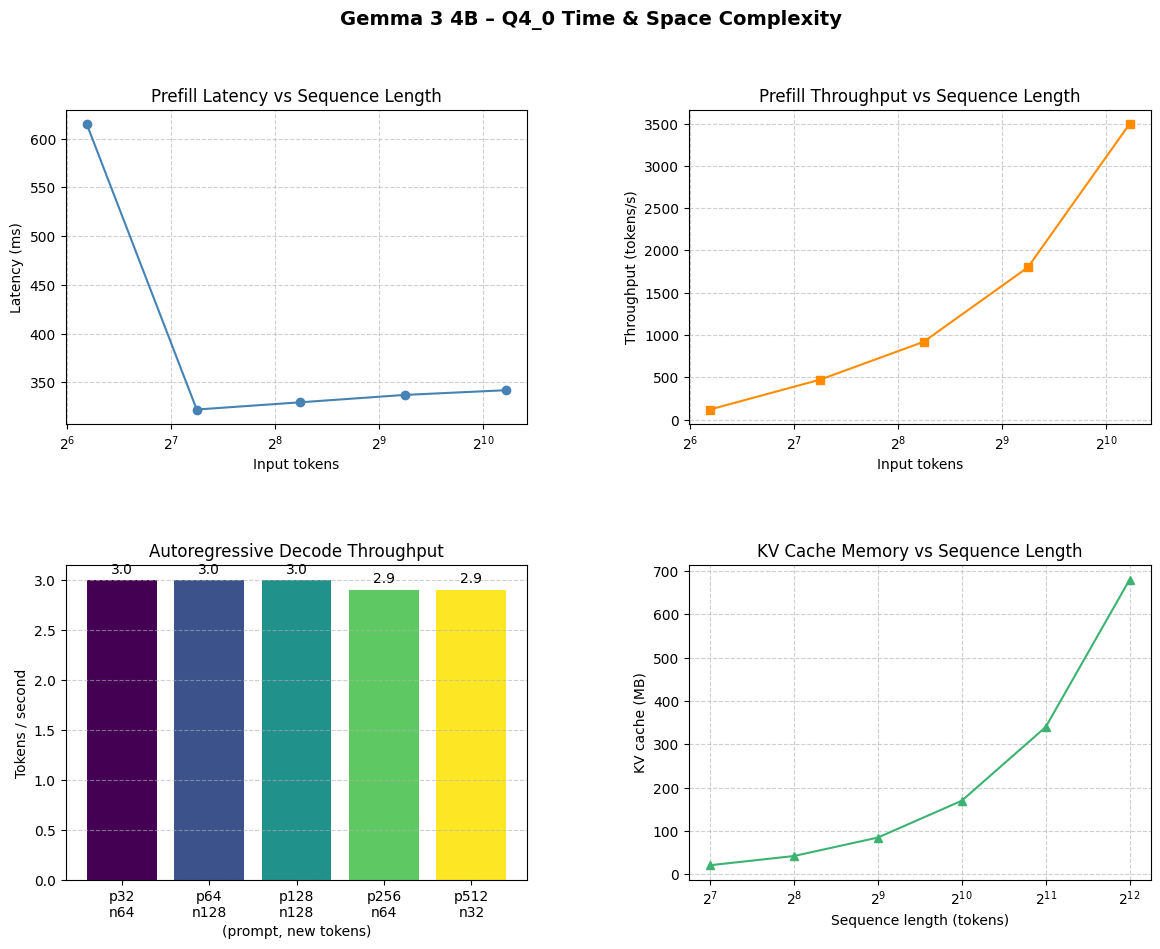

Figure saved → q4_0_complexity_gemma3_4b_20260324_064925.png


In [11]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from datetime import datetime

run_ts   = datetime.now().strftime("%Y%m%d_%H%M%S")
fig_path = f"q4_0_complexity_gemma3_4b_{run_ts}.png"

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

# Prefill latency
ax1 = fig.add_subplot(gs[0, 0])
if prefill_results:
    xs = [r["actual_tokens"] for r in prefill_results]
    ax1.plot(xs, [r["mean_ms"] for r in prefill_results], marker="o", color="steelblue")
    ax1.set_xlabel("Input tokens"); ax1.set_ylabel("Latency (ms)")
    ax1.set_title("Prefill Latency vs Sequence Length")
    ax1.set_xscale("log", base=2); ax1.grid(True, linestyle="--", alpha=0.6)

# Prefill throughput
ax2 = fig.add_subplot(gs[0, 1])
if prefill_results:
    ax2.plot(xs, [r["tokens_per_sec"] for r in prefill_results], marker="s", color="darkorange")
    ax2.set_xlabel("Input tokens"); ax2.set_ylabel("Throughput (tokens/s)")
    ax2.set_title("Prefill Throughput vs Sequence Length")
    ax2.set_xscale("log", base=2); ax2.grid(True, linestyle="--", alpha=0.6)

# Decode throughput
ax3 = fig.add_subplot(gs[1, 0])
if decode_results:
    labels = [f"p{r['prompt_tokens']}\nn{r['new_tokens']}" for r in decode_results]
    vals   = [r["tokens_per_sec"] for r in decode_results]
    colors = plt.cm.viridis([i / max(len(vals)-1,1) for i in range(len(vals))])
    bars   = ax3.bar(labels, vals, color=colors)
    ax3.set_xlabel("(prompt, new tokens)"); ax3.set_ylabel("Tokens / second")
    ax3.set_title("Autoregressive Decode Throughput")
    ax3.bar_label(bars, fmt="%.1f", padding=3)
    ax3.grid(axis="y", linestyle="--", alpha=0.6)

# KV cache
ax4 = fig.add_subplot(gs[1, 1])
kv_seq = [128, 256, 512, 1024, 2048, 4096]
kv_mb  = [2 * N_LAYERS * s * N_KV_HEADS * HEAD_DIM * 2 / 1024**2 for s in kv_seq]
ax4.plot(kv_seq, kv_mb, marker="^", color="mediumseagreen")
ax4.set_xlabel("Sequence length (tokens)"); ax4.set_ylabel("KV cache (MB)")
ax4.set_title("KV Cache Memory vs Sequence Length")
ax4.set_xscale("log", base=2); ax4.grid(True, linestyle="--", alpha=0.6)

plt.suptitle(f"Gemma 3 4B – Q4_0 Time & Space Complexity", fontsize=14, fontweight="bold")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figure saved → {fig_path}")

### Optional: Copy Results to Google Drive

In [12]:
from google.colab import drive
import shutil, glob, os

drive.mount('/content/drive')
dest = '/content/drive/MyDrive/llm_complexity/gemma3_4b_q4_0'
os.makedirs(dest, exist_ok=True)

for pattern in [
    f"complexity_results_gemma3_4b/*.json",
    f"complexity_results_gemma3_4b/*.csv",
    f"q4_0_complexity_gemma3_4b_*.png",
]:
    for src in glob.glob(pattern):
        shutil.copy(src, dest)
        print(f"Copied {src} → {dest}/")
print("Done.")

Mounted at /content/drive
Copied complexity_results_gemma3_4b/results_20260324_064925.json → /content/drive/MyDrive/llm_complexity/gemma3_4b_q4_0/
Copied complexity_results_gemma3_4b/decode_20260324_064925.csv → /content/drive/MyDrive/llm_complexity/gemma3_4b_q4_0/
Copied complexity_results_gemma3_4b/space_20260324_064925.csv → /content/drive/MyDrive/llm_complexity/gemma3_4b_q4_0/
Copied complexity_results_gemma3_4b/prefill_20260324_064925.csv → /content/drive/MyDrive/llm_complexity/gemma3_4b_q4_0/
Copied q4_0_complexity_gemma3_4b_20260324_064925.png → /content/drive/MyDrive/llm_complexity/gemma3_4b_q4_0/
Done.


### Summary

In [13]:
print("=" * 60)
print(f"  {MODEL_NAME} – Q4_0 COMPLEXITY SUMMARY")
print("=" * 60)
print(f"  Params (approx):       {TOTAL_PARAMS/1e9:.3f} B")
print(f"  GGUF file size:        {file_gb:.3f} GB")
print(f"  RAM after load:        {ram_used_gb:.3f} GB")
print(f"  vs fp32:               {TOTAL_PARAMS*4/file_bytes:.1f}x smaller")
print(f"  Layers / KV heads:     {N_LAYERS} / {N_KV_HEADS}")
if len(prefill_results) >= 2:
    r0, r1 = prefill_results[0], prefill_results[-1]
    ratio    = r1["mean_ms"] / r0["mean_ms"] if r0["mean_ms"] else float("nan")
    expected = (r1["actual_tokens"] / r0["actual_tokens"]) ** 2
    print(f"  Prefill @ {r0['actual_tokens']:>5} tok:    {r0['mean_ms']:>8.2f} ms")
    print(f"  Prefill @ {r1['actual_tokens']:>5} tok:    {r1['mean_ms']:>8.2f} ms")
    print(f"  Observed scaling:      {ratio:.2f}x  (O(n²) predicts {expected:.0f}x)")
if decode_results:
    best = max(decode_results, key=lambda r: r["tokens_per_sec"])
    print(f"  Best decode speed:     {best['tokens_per_sec']} tok/s")
print("=" * 60)

  Gemma 3 4B – Q4_0 COMPLEXITY SUMMARY
  Params (approx):       4.300 B
  GGUF file size:        2.207 GB
  RAM after load:        4.145 GB
  vs fp32:               7.3x smaller
  Layers / KV heads:     34 / 4
  Prefill @    73 tok:      615.29 ms
  Prefill @  1196 tok:      342.03 ms
  Observed scaling:      0.56x  (O(n²) predicts 268x)
  Best decode speed:     3.0 tok/s
